# 08 · The improved model against other tools

**Question:** how does the improved model compare with the open tools used to map deforestation risk for jurisdictions and REDD+ projects, on the same data, windows and scores? The methodology document names these tools (§2.7) but compares the deployed model only with forestatrisk, as a check of its code.

| Tool | How it runs here |
|---|---|
| riskmapjnr (Vieilledent 2023) | Its moving-window method on the shares, step by step as riskmapjnr 1.3.2: the local annual loss rate in a window (1.3, 2.7 or 5.1 km), zero risk beyond the distance from non-forest holding 99.5 % of the loss, 30 classes by equal area or equal interval, each class's observed rate. Like the package's `makemap`, it keeps the window and slicing with the lowest wRMSE in the test window. On the shares, a window's sums are those of the 30 m pixels it would count at its own resolution. The package itself needs each cell marked lost or kept, which at 100 m means a rule notebook 04 rejected. **Compared with the same timing as every other model** (section 4) |
| forestatrisk (Vieilledent et al. 2022) | Its binomial iCAR model, run with its own code, on the improved model's 16 predictors: logistic regression plus a spatial random effect for each 10 km cell. Training cells drawn in proportion to their lost and kept forest (as sampling 30 m pixels) |
| Weights of evidence | Dinamica EGO's method (Bonham-Carter 1994), written here: each predictor in 10 ranges, weighted by the lost and kept forest (ha) in each |
| Improved model | Notebook 07, trained on the shares |
| Rank average | The improved model and riskmapjnr's local rate, each cell's mean percentile rank |

All are scored as in notebook 03: AUC over the 30 m forest pixels and Verra's two tests with forest and loss in hectares. The benchmark and the deployed model come from notebook 03.

**Same timing for every model.** Each model's calibration map uses what is known at the start of the calibration window (T1), and its test map what is known at T2, as VT0007 does for its benchmark (distance from non-forest at T1, then at T2). riskmapjnr, as designed, builds its calibration map from the loss of the calibration window itself; for the comparison it is given the loss of the three years before T1 instead. Its test map is unchanged. Section 4 shows it as designed, and what the literature says about the two. The code is `scripts/tool_comparison.py` (forestatrisk: `scripts/tools_forestatrisk.py`). Results are saved in `outputs/runs/`; set `RERUN = True` to compute them again (about 20 minutes per window).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "scripts"))
import model as MM
import tool_comparison as T
import verra as V

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = HERE.parent / "outputs" / "summary"
RERUN = False
runs = [MM.cached(T.split_name(s), lambda s=s: T.run_split(s), rerun=RERUN) for s in MM.SPLITS]
step5 = [MM.cached(V.split_name(s), lambda s=s: V.run_split(s)) for s in MM.SPLITS]
same = [MM.cached(T.split_name(s).replace("tools_", "tools_same_timing_"), lambda s=s: T.run_same_timing(s), rerun=RERUN)
        for s in MM.SPLITS]

## 1 · riskmapjnr on the shares

First, a check of the code: the local rate written here against the package's own (`local_defor_rate`), on the same forest-change raster: a block of 1,000 × 1,000 cells of the platform's grid (forest-savanna around Kissidougou), with the loss of 2014–2016.

In [2]:
check = MM.cached("riskmapjnr_check", T.check_against_package)
print(f"{check['block']['forest_cells']:,} forest cells, {check['block']['cells_with_loss']:,} with loss")
pd.DataFrame({f"Window of {ws} cells": check[str(ws)] for ws in (5, 11, 21)}).T

891,769 forest cells, 81,029 with loss


,identical,largest_difference
Window of 5 cells,1.0,0.0
Window of 11 cells,1.0,0.0
Window of 21 cells,1.0,0.0


In [3]:
choice = pd.DataFrame([{"Window": run["split"], "Distance threshold (m)": run["riskmapjnr_choice"]["dist_thresh_m"],
                        **{f"{m['ws']} cells, {'equal area' if m['m'] == 'ea' else 'equal interval'}": m["wRMSE"]
                           for m in run["riskmapjnr_choice"]["models"]},
                        "Chosen": f"{run['riskmapjnr_choice']['ws_hat']} cells, "
                                  f"{'equal area' if run['riskmapjnr_choice']['m_hat'] == 'ea' else 'equal interval'}"}
                       for run in same]).set_index("Window")
print("riskmapjnr's validation error (wRMSE, ha) for each window size and slicing, on 10 km squares (same timing)")
choice

riskmapjnr's validation error (wRMSE, ha) for each window size and slicing, on 10 km squares (same timing)


,Distance threshold (m),"13 cells, equal interval","13 cells, equal area","27 cells, equal interval","27 cells, equal area","51 cells, equal interval","51 cells, equal area",Chosen
Window,,,,,,,,
2014–2016 → 2017–2019,1200.005489,352.7,325.5,304.6,276.1,294.5,256.1,"51 cells, equal area"
2017–2019 → 2020–2022,800.003659,208.3,183.2,148.9,123.9,131.3,102.5,"51 cells, equal area"
2019–2021 → 2022–2024,600.002745,156.3,128.3,125.2,91.8,126.6,91.5,"51 cells, equal area"


**Reading:**

* **The code matches the package:** on the block of the platform's grid, the local rate written here equals the package's in every forest cell, for all three window sizes.
* **riskmapjnr chooses the 5 km window with equal-area classes in every window**, with either timing. Its choice uses the test window, as `makemap` is designed to, but the choice is always the same, so it gives no advantage here.
* **Its distance threshold falls from 1.2 km to 0.6 km over the three windows** as the forest becomes more fragmented: the loss happens ever closer to non-forest.

## 2 · Every tool, every window

In [4]:
rows = []
for run, base, fair in zip(runs, step5, same):
    bench = base["models"]["benchmark"]
    entries = {"VT0007 benchmark": bench, "Deployed model (platform)": base["models"]["deployed_half"],
               **run["tools"], **fair["tools"]}                    # riskmapjnr and the rank average: same timing
    for name, r in entries.items():
        rows.append({"Window": run["split"], "Tool": name, "AUC": np.mean(r["aucs"]),
                     "Fit MedAE (ha)": r["fit_medae_ha"], "Prediction MedAE (ha)": r["prediction_medae_ha"],
                     "Beats the benchmark on both tests": "–" if name == "VT0007 benchmark" else
                     ("yes" if r["fit_medae_ha"] < bench["fit_medae_ha"] and r["prediction_medae_ha"] < bench["prediction_medae_ha"] else "no")})
tools = pd.DataFrame(rows)
tools.round(4).to_csv(OUT / "08_tools.csv", index=False)
tools.set_index(["Window", "Tool"]).round(3)

AUC  \
Window                Tool                                                 
2014–2016 → 2017–2019 VT0007 benchmark                             0.694   
                      Deployed model (platform)                    0.717   
                      riskmapjnr (moving window)                   0.764   
                      Weights of evidence (Dinamica EGO's method)  0.733   
                      forestatrisk (iCAR)                          0.757   
                      Improved model                               0.757   
                      Rank average: improved model + riskmapjnr    0.773   
2017–2019 → 2020–2022 VT0007 benchmark                             0.673   
                      Deployed model (platform)                    0.681   
                      riskmapjnr (moving window)                   0.758   
                      Weights of evidence (Dinamica EGO's method)  0.734   
                      forestatrisk (iCAR)                          0.754   
                      Improved model                               0.763   
                      Rank average: improved model + riskmapjnr    0.767   
2019–2021 → 2022–2024 VT0007 benchmark                             0.638   
                      Deployed model (platform)                    0.631   
                      riskmapjnr (moving window)                   0.728   
                      Weights of evidence (Dinamica EGO's method)  0.709   
                      forestatrisk (iCAR)                          0.725   
                      Improved model                               0.737   
                      Rank average: improved model + riskmapjnr    0.737   

                                                                   Fit MedAE (ha)  \
Window                Tool                                                          
2014–2016 → 2017–2019 VT0007 benchmark                                    251.760   
                      Deployed model (platform)                           129.938   
                      riskmapjnr (moving window)                          232.006   
                      Weights of evidence (Dinamica EGO's method)         200.527   
                      forestatrisk (iCAR)                                 143.405   
                      Improved model                                      107.716   
                      Rank average: improved model + riskmapjnr           158.352   
2017–2019 → 2020–2022 VT0007 benchmark                                    385.399   
                      Deployed model (platform)                           185.083   
                      riskmapjnr (moving window)                          123.792   
                      Weights of evidence (Dinamica EGO's method)         268.569   
                      forestatrisk (iCAR)                                 130.294   
                      Improved model                                      149.596   
                      Rank average: improved model + riskmapjnr           126.755   
2019–2021 → 2022–2024 VT0007 benchmark                                    422.414   
                      Deployed model (platform)                           156.374   
                      riskmapjnr (moving window)                          136.974   
                      Weights of evidence (Dinamica EGO's method)         222.561   
                      forestatrisk (iCAR)                                 128.450   
                      Improved model                                      127.629   
                      Rank average: improved model + riskmapjnr           122.864   

                                                                   Prediction MedAE (ha)  \
Window                Tool                                                                 
2014–2016 → 2017–2019 VT0007 benchmark                                           445.637   
                      Deployed model (platform)                                  278.241

## 3 · Mean of the three windows

In [5]:
mean100 = tools.groupby("Tool", sort=False).agg(**{"AUC": ("AUC", "mean"), "Fit MedAE (ha)": ("Fit MedAE (ha)", "mean"),
                                                   "Prediction MedAE (ha)": ("Prediction MedAE (ha)", "mean"),
                                                   "Windows beating the benchmark": ("Beats the benchmark on both tests", lambda v: int((v == "yes").sum()))})
mean100.loc["VT0007 benchmark", "Windows beating the benchmark"] = np.nan
mean100.round(3).to_csv(OUT / "08_tools_mean.csv")
mean100.round(3)

,AUC,Fit MedAE (ha),Prediction MedAE (ha),Windows beating the benchmark
Tool,,,,
VT0007 benchmark,0.668,353.191,373.212,NaN
Deployed model (platform),0.676,157.131,236.017,3.0
riskmapjnr (moving window),0.750,164.258,193.343,3.0
Weights of evidence (Dinamica EGO's method),0.725,230.552,277.017,3.0
forestatrisk (iCAR),0.745,134.050,244.967,3.0
Improved model,0.752,128.314,179.526,3.0
Rank average: improved model + riskmapjnr,0.759,135.990,172.961,3.0


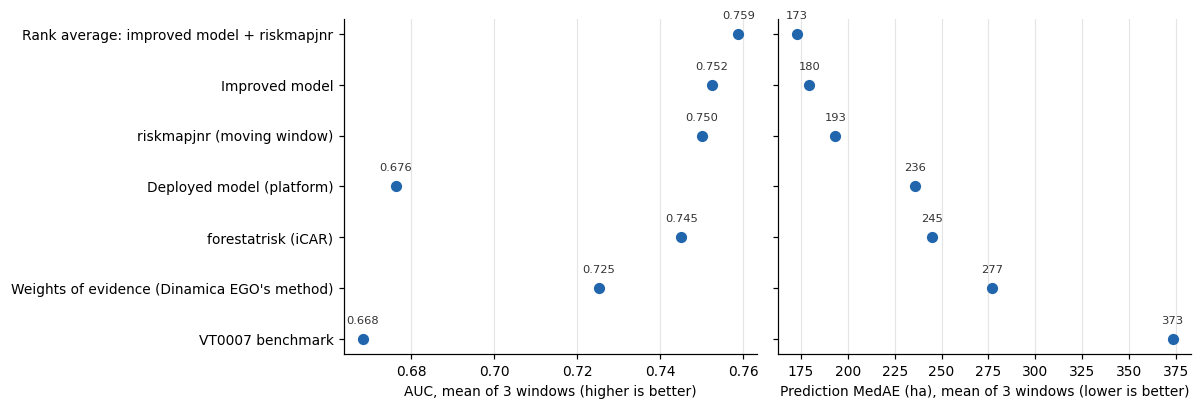

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = mean100.sort_values("Prediction MedAE (ha)", ascending=False).index
y = np.arange(len(order))
for ax, column in zip(axes, ["AUC", "Prediction MedAE (ha)"]):
    ax.scatter(mean100.loc[order, column], y, s=40, color="#2166ac", zorder=3)
    for yi, v in zip(y, mean100.loc[order, column]):
        ax.text(v, yi + 0.3, f"{v:.3f}" if column == "AUC" else f"{v:.0f}", ha="center", fontsize=7.5, color="#333")
    ax.set_yticks(y, order)
    ax.set_xlabel(f"{column}, mean of 3 windows" + (" (higher is better)" if column == "AUC" else " (lower is better)"))
    ax.grid(axis="x", color="#e5e5e5", zorder=0)
plt.tight_layout(); plt.show()

**Reading** (same timing for every model):

* **Every tool beats the benchmark on both of Verra's tests in every window.**
* **The improved model has the best fit test (128 ha) and, with the rank average, the best prediction test.** The rank average averages 173 ha and the improved model 180. riskmapjnr follows at 193 ha, forestatrisk at 245 and weights of evidence at 277. No tool is best in every window: the improved model leads in the first (234 ha), riskmapjnr in the second (150), the rank average in the third (122).
* **The improved model and riskmapjnr rank cells about equally** (AUC 0.752 and 0.750). Their rank average ranks best (0.759).
* **forestatrisk ranks nearly as well** (AUC 0.745), but its prediction test swings from 408 to 141 ha between windows. Weights of evidence stays behind.
* **The deployed model passes Verra's tests but ranks loss barely above the benchmark** (AUC 0.676 against 0.668), because its half-cell masks leave part of the forest out (notebook 03).

## 4 · riskmapjnr as designed

In [7]:
rows = []
for run, fair in zip(runs, same):
    for label, source in (("As designed: calibration map from the calibration window's own loss", run),
                          ("Same timing as the other models: calibration map from the 3 years before", fair)):
        r = source["tools"]["riskmapjnr (moving window)"]
        rows.append({"Window": run["split"], "riskmapjnr": label, "AUC": np.mean(r["aucs"]),
                     "Fit MedAE (ha)": r["fit_medae_ha"], "Prediction MedAE (ha)": r["prediction_medae_ha"]})
designed = pd.DataFrame(rows)
designed.round(4).to_csv(OUT / "08_riskmapjnr_as_designed.csv", index=False)
table = designed.pivot(index="riskmapjnr", columns="Window", values="Prediction MedAE (ha)")
table["Mean"] = table.mean(axis=1)
table["Fit MedAE, mean (ha)"] = designed.groupby("riskmapjnr")["Fit MedAE (ha)"].mean()
print("Prediction MedAE (ha) by test window; the test map and its AUC are the same in both")
table.round(1)

Prediction MedAE (ha) by test window; the test map and its AUC are the same in both


Window,2014–2016 → 2017–2019,2017–2019 → 2020–2022,2019–2021 → 2022–2024,Mean,"Fit MedAE, mean (ha)"
riskmapjnr,,,,,
As designed: calibration map from the calibration window's own loss,187.6,121.0,117.1,141.9,21.8
Same timing as the other models: calibration map from the 3 years before,280.1,149.9,150.1,193.3,164.3


**Reading:**

* **As designed, riskmapjnr has the lowest prediction error of all (142 ha) and a fit error of 22 ha.** With the same timing as the other models, these become 193 and 164 ha. The test map is the same in both, so the whole difference comes from the calibration map, which sets each class's loss rate.
* **Its fit test is near-circular as designed.** The calibration map is the local rate of the very loss the fit test measures.
* **The steeper class rates it learns that way also help its prediction test.** They put most of the next window's loss where loss just happened. The median error over 185 blocks probably rewards this, because most blocks have little loss.

**What the sources say about the calibration map**

| Source | Calibration map | Tests |
|---|---|---|
| Verra, JNR Risk Mapping Tool, draft for public consultation (2021), the method riskmapjnr implements | "The risk maps to be evaluated and compared shall be created with data from the calibration period only": the local rate of the calibration period's own loss, on the hypothesis that the recent past's local rates predict the immediate future | Prediction only (wRMSE in the validation period); no fit test |
| riskmapjnr and the deforisk QGIS plugin (Vieilledent, CIRAD) | The same: the moving-window map is "fitted over the calibration period (t1–t2)" and used for the prediction at t2 | deforisk adds VT0007's fit and prediction tests (forestatrisk's `validation_udef_arp`) to the same maps |
| Verra, VT0007 v1.0 (2024), section 5.1 | "The model used in the prediction phase is the same as for the fitting phase except that the values of any dynamic variables – maps that change over time – … must be updated before the model is applied for prediction" | Fit and prediction tests; a model must beat the benchmark on both |
| VT0007 v1.0, benchmark (sections 5.2, 5.3) | Inputs dated at the start of each phase: "In the fitting phase … use distance from non-forest at T1. For the prediction phase, this variable will have changed and must be updated … distance from non-forest at T2" | – |

So the 2021 draft and its tools support riskmapjnr's design. VT0007 v1.0 adds the fit test, asks for dynamic variables to be updated between phases, and dates its own benchmark's inputs at the start of each phase. That supports the same timing for every model, but VT0007 v1.0 does not state it for alternative models. riskmapjnr as designed keeps one map (the calibration window's loss) for both phases, so nothing is updated between them. For comparing the tools here, every model has the same timing.

## 5 · What this means

* **With the same timing for every model, the improved model is the best single model.** It has the best fit test, the second-best prediction test (180 ha, behind its rank average with riskmapjnr at 173) and the best AUC of the single models.
* **riskmapjnr leads only as designed**, with its calibration map built from the calibration window's own loss. That design comes from Verra's 2021 draft tool.
* **Open decision: how the calibration map is built** (sources in section 4).
  * **A. Same timing for every model** (VT0007 v1.0's rule for dynamic variables and its benchmark): the improved model leads.
  * **B. riskmapjnr as designed** (the 2021 draft tool): riskmapjnr leads (142 ha).
  * The choice does not change the AUC, since the test map is the same either way.
  * Notebook 10 examines it (the sources, other scores, models for option B) and recommends option A, with the rank average of the improved model and riskmapjnr as the platform's risk map: it is the most consistent model across scores and block sizes.
* **Notebook 09** tests whether the improved model can take what the tools and the platform do differently.